In [2]:
import shap
import pandas as pd
import xgboost as xgb
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split


In [ ]:
df = pd.read_csv('../../../datasets/balanceados/dataset_fluxo_balanceado.csv')
drop_columns = ['Average Packet Size', 'Packet Length Std', 'Packet Length Mean']
df.drop(columns=drop_columns, inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 19 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Flow Bytes/s                 104802 non-null  float64
 5   Flow Packets/s               104802 non-null  float64
 6   Flow IAT Mean                104802 non-null  float64
 7   Flow IAT Std                 104802 non-null  float64
 8   Flow IAT Max                 104802 non-null  float64
 9   Flow IAT Min                 104802 non-null  float64
 10  Fwd Packets/s                104802 non-null  float64
 11  Bwd Packets/s                104802 non-null  float64
 12  Packet Length Variance       104802 non-null  float64
 13  Down/Up Ra

In [4]:
x=df.drop(columns=['Label'])
y=df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)

DT

In [5]:
modelo_dt = tree.DecisionTreeClassifier(random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
matriz_dt1 = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    matriz_dt1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9893
Acurácia:  98.6928
Precisão:  98.7064
Recall:    98.6875
F1-Score:  98.6925

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.01%                1.99%
Real: 1 (Ataque)                0.63%               99.37%


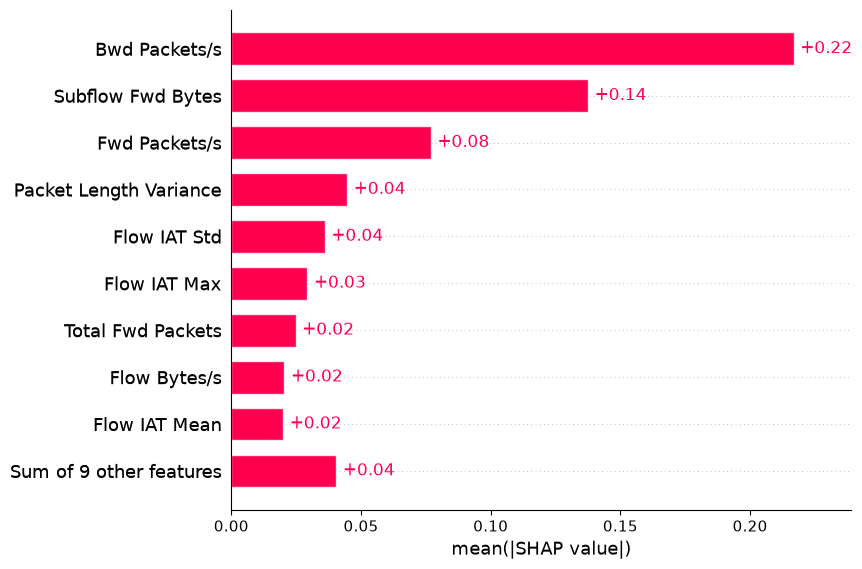

In [6]:
explainer_dt = shap.TreeExplainer(modelo_dt)
shap_values = explainer_dt(amostra_500)

shap.plots.bar(shap_values[:, :, 1])

RF

In [7]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9892
Acurácia:  98.7310
Precisão:  98.7424
Recall:    98.7262
F1-Score:  98.7307

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.12%                1.88%
Real: 1 (Ataque)                0.66%               99.34%


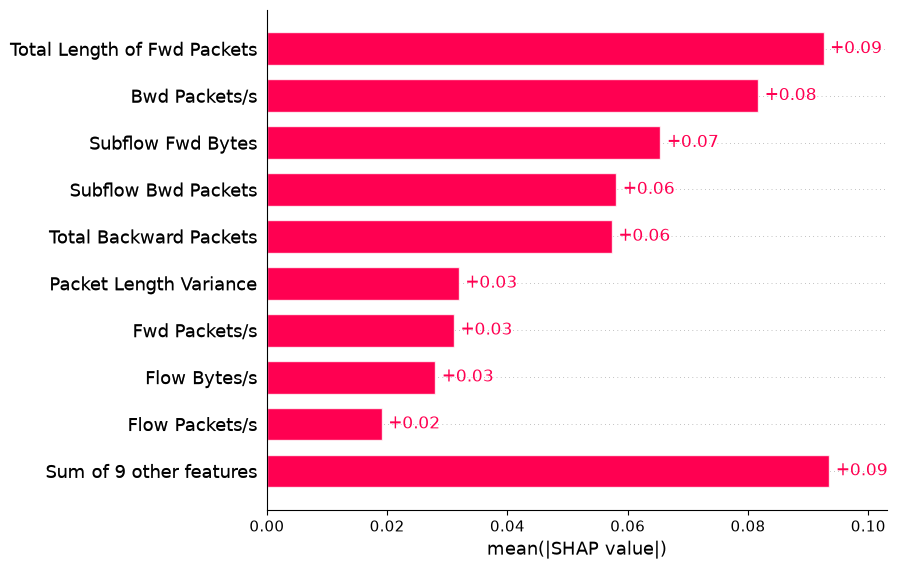

In [10]:
explainer_rf = shap.TreeExplainer(modelo_rf)
shap_values_rf = explainer_rf(amostra_500)        

shap.plots.bar(shap_values_rf[:, :, 1])

XGB

In [11]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9889
Acurácia:  98.7167
Precisão:  98.7274
Recall:    98.7120
F1-Score:  98.7164

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.12%                1.88%
Real: 1 (Ataque)                 0.7%                99.3%


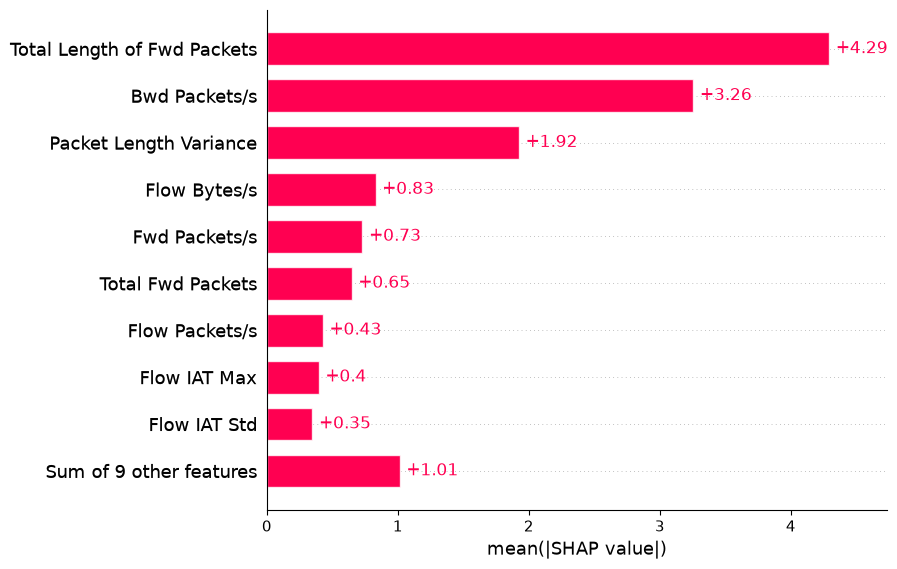

In [12]:
explainer_xgb = shap.TreeExplainer(modelo_xgb)
shap_values_xgb = explainer_xgb(amostra_500)

shap.plots.bar(shap_values_xgb)

SVM

In [13]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.8979
Acurácia:  89.8240
Precisão:  89.9130
Recall:    89.8058
F1-Score:  89.8147

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)                87.5%                12.5%
Real: 1 (Ataque)                7.89%               92.11%


Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


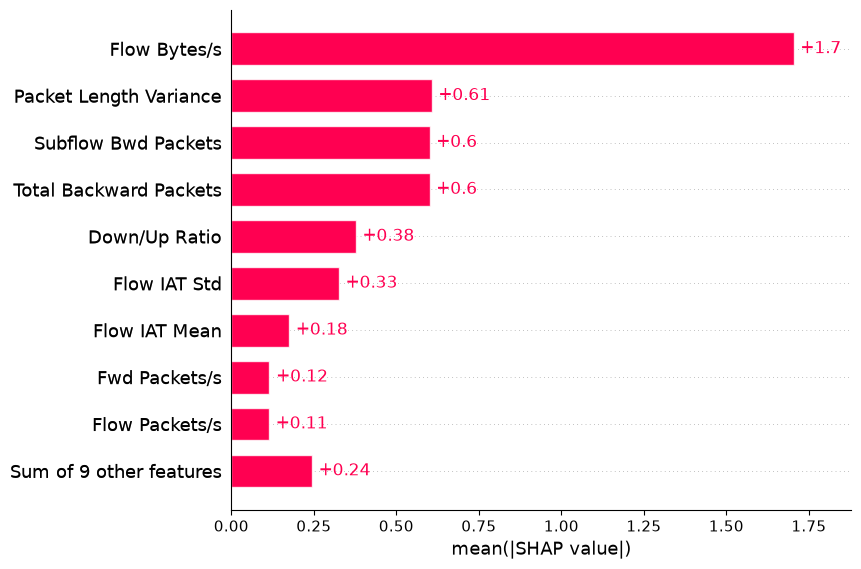

In [ ]:
explainer_svm = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values_svm = explainer_svm(amostra_500)

shap.plots.bar(shap_values_svm)    

KNN

In [15]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9875
Acurácia:  98.5974%
Precisão:  98.6100%
Recall:    98.5923%
F1-Score:  98.5971%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.94%                2.06%
Real: 1 (Ataque)                0.76%               99.24%


PermutationExplainer explainer: 101it [03:29,  2.13s/it]                         


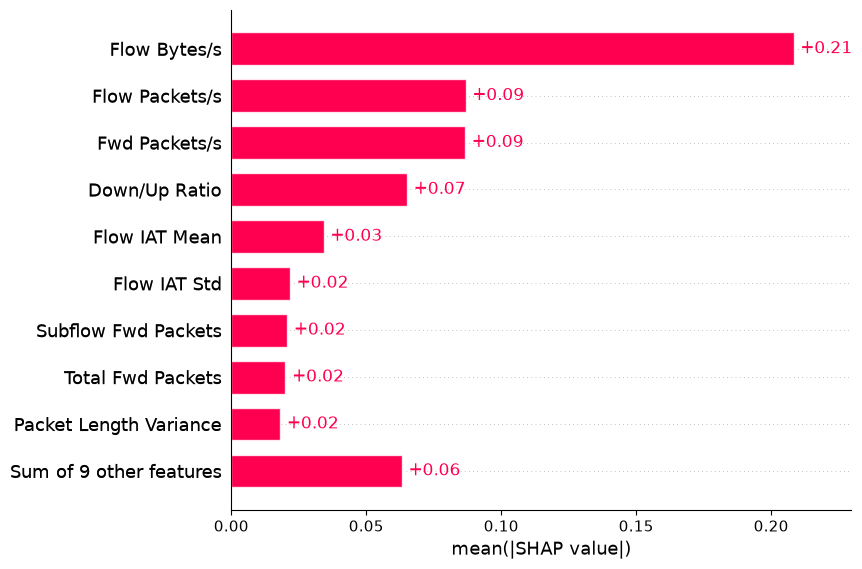

In [16]:
explainer_knn = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_knn = explainer_knn(amostra_100)

shap.plots.bar(shap_values_knn[:,:, 1])

MLP

In [17]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9862
Acurácia:  98.5401
Precisão:  98.5473
Recall:    98.5365
F1-Score:  98.5399

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.08%                1.92%
Real: 1 (Ataque)                 1.0%                99.0%


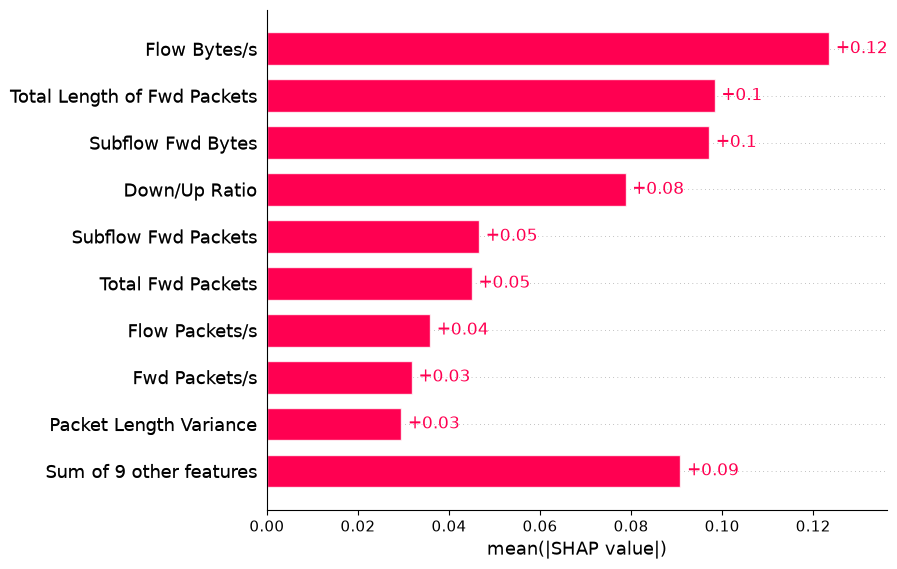

In [18]:
explainer_mlp = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_mlp = explainer_mlp(amostra_100)

shap.plots.bar(shap_values_mlp[:, :, 1])